# Principal Component Analysis of SDSS DR17 galaxies

We compare PCA of photometric magnitudes and colour indices using the correlation matrix. Finally, we investigate the sensitivity of colour PCA to extreme observations.

## Import cleaned data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
from IPython.display import display

# Consistent style for all figures
sns.set_theme(style="ticks", context="notebook", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
FIGURES = Path("figures/pca")
FIGURES.mkdir(parents=True, exist_ok=True)
BLUE = "#4477AA"
ORANGE = "#CC6677"
VARIANCE_THRESHOLD = 0.95

In [2]:
df = pd.read_parquet("cleaned_sdss17_gal.parquet")
features = ["u", "g", "r", "i", "z"]

# Check the inputs without changing the shared sample.
if not np.isfinite(df[features + ["redshift"]].to_numpy()).all():
    raise ValueError("Non-finite photometry or redshift: check preprocessing.")

redshift_norm = Normalize(df["redshift"].min(), df["redshift"].max())
print(f"Number of galaxies: {len(df):,}")
df.head()

Number of galaxies: 11,030


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,...,sn_g,sn_r,sn_i,sn_z,u-g,g-r,r-i,i-z,u-r,M_r
0,1237680272041378048,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,...,1027.750245,2094.169842,2255.048644,820.645052,1.85690,1.08281,0.52036,0.43250,2.93971,-22.165532
1,1237651539783057664,167.131669,67.339936,20.48292,18.67807,17.61680,17.11936,16.73351,1412,301,...,373.911561,746.928828,787.508590,274.530270,1.80485,1.06127,0.49744,0.38585,2.86612,-20.953227
2,1237662341086970112,241.426267,27.224695,18.88323,17.54229,17.01789,16.75376,16.72259,3927,301,...,1064.347922,1296.712632,1102.797170,277.305416,1.34094,0.52440,0.26413,0.03117,1.86534,-18.724704
3,1237663478723575808,337.093435,-0.311773,20.15491,18.37295,17.31276,16.82294,16.44342,4192,301,...,495.242867,988.315384,1034.721789,358.615142,1.78196,1.06019,0.48982,0.37952,2.84215,-21.925003
4,1237662341086642432,240.664803,27.586545,19.18550,18.02785,17.46046,17.14015,16.97431,3927,301,...,680.548471,862.611843,772.572548,219.921162,1.15765,0.56739,0.32031,0.16584,1.72504,-20.592046


### PCA methodology

We centre and standardize each feature, construct the correlation matrix $S=Z^T Z/N$ and diagonalize it using `np.linalg.eigh`. Eigenvalues are sorted in descending order. The scores are the projections onto the eigenvectors. We retain the smallest number of components explaining at least 95% of the variance. The sign of each eigenvector is arbitrary.

The same function is used for all three PCA calculations.

In [3]:
def correlation_pca(X):
    # Standardize each column to zero mean and unit variance.
    std = X.std(axis=0)
    if np.any(std == 0):
        raise ValueError("PCA requires non-constant features.")
    Z = (X - X.mean(axis=0)) / std

    # Correlation matrix and eigenvalue decomposition
    S = Z.T @ Z / len(Z)
    eigenvalues, eigenvectors = np.linalg.eigh(S)

    # Sort components by decreasing variance.
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Explained variance and number of retained components
    explained = eigenvalues / eigenvalues.sum()
    cumulative = np.cumsum(explained)
    k = np.searchsorted(cumulative, VARIANCE_THRESHOLD) + 1

    # Project onto all components for interpretation.
    scores = Z @ eigenvectors
    return S, eigenvalues, eigenvectors, explained, cumulative, k, scores

### Shared plotting helpers

Each figure is saved as PDF for LaTeX and PNG for convenient preview. Heatmaps share the same colour scale; redshift plots share the same normalization.

In [4]:
def save_figure(fig, name):
    fig.tight_layout()
    for extension in ("pdf", "png"):
        fig.savefig(FIGURES / f"{name}.{extension}", bbox_inches="tight")
    plt.show()
    plt.close(fig)


def heatmap(ax, values, rows, columns, title, fmt=".2f"):
    sns.heatmap(values, annot=True, fmt=fmt, cmap="RdBu_r",
                vmin=-1, vmax=1, center=0, linewidths=0.4,
                xticklabels=columns, yticklabels=rows, ax=ax,
                cbar_kws={"shrink": 0.85})
    ax.set_title(title)
    ax.tick_params(axis="y", labelrotation=0)


def pc_labels(n):
    return [f"PC{i + 1}" for i in range(n)]


def variance_plot(explained, cumulative, title, name):
    fig, ax = plt.subplots(figsize=(7, 4))
    pcs = np.arange(1, len(explained) + 1)
    ax.bar(pcs, 100 * explained, color=BLUE, label="Individual")
    ax.plot(pcs, 100 * cumulative, "o-", color=ORANGE, label="Cumulative")
    ax.axhline(100 * VARIANCE_THRESHOLD, color="0.35", linestyle="--",
               label="95% threshold")
    ax.set(xlabel="Principal component", ylabel="Explained variance (%)",
           xticks=pcs, ylim=(0, 105), title=title)
    ax.legend(frameon=False)
    save_figure(fig, name)


def score_plot(scores, explained, title, name, redshift=None):
    fig, ax = plt.subplots(figsize=(7, 5))
    if redshift is None:
        ax.scatter(scores[:, 0], scores[:, 1], s=5, alpha=0.35,
                   color=BLUE, rasterized=True)
    else:
        points = ax.scatter(scores[:, 0], scores[:, 1], c=redshift,
                            cmap="viridis", norm=redshift_norm,
                            s=5, alpha=0.55, rasterized=True)
        fig.colorbar(points, ax=ax, label="Redshift")
    ax.set(xlabel=f"PC1 ({explained[0]:.1%})",
           ylabel=f"PC2 ({explained[1]:.1%})", title=title)
    save_figure(fig, name)


def colour_plot(colours, redshift, name, zoom=False):
    fig, ax = plt.subplots(figsize=(7, 5))
    points = ax.scatter(colours["r-i"], colours["i-z"], c=redshift,
                        cmap="viridis", norm=redshift_norm,
                        s=5, alpha=0.55, rasterized=True)
    rho = colours["r-i"].corr(colours["i-z"])
    title = f"Colour-colour diagram (r = {rho:.3f})"
    if zoom:
        ax.set(xlim=(-0.5, 1.0), ylim=(-0.5, 1.0))
        title = "Colour-colour diagram (zoomed; full-sample r shown)" + f"\n r = {rho:.3f}"
    ax.set(xlabel="r-i", ylabel="i-z", title=title)
    fig.colorbar(points, ax=ax, label="Redshift")
    save_figure(fig, name)

## 1. PCA with magnitudes

We use the five observed SDSS magnitudes. Redshift is not a PCA input, but is retained for interpretation.

In [5]:
X = df[features].to_numpy()
S, eigenvalues, eigenvectors, explained, cumulative, k, scores = correlation_pca(X)
PC = scores[:, :k]

print("Eigenvalues:", eigenvalues.round(4))
print("Explained variance:", explained.round(4))
print("Number of retained PCs:", k)
print(f"Total retained variance: {cumulative[k - 1]:.2%}")

Eigenvalues: [4.4924 0.4429 0.033  0.0257 0.006 ]
Explained variance: [0.8985 0.0886 0.0066 0.0051 0.0012]
Number of retained PCs: 2
Total retained variance: 98.71%


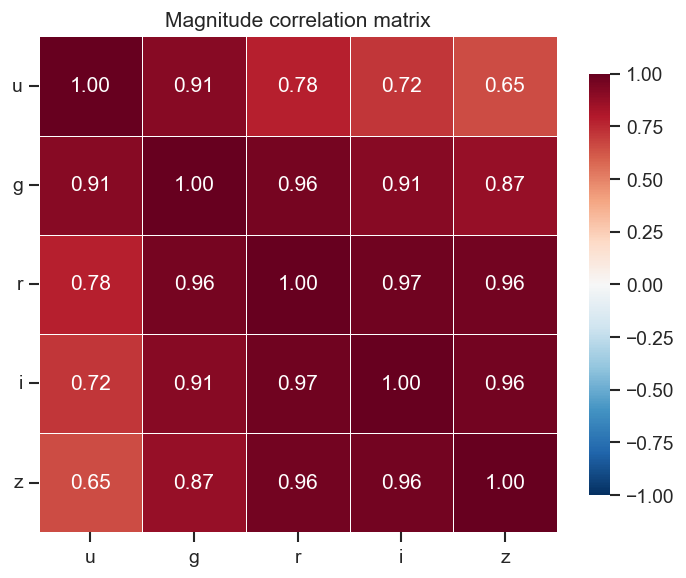

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
heatmap(ax, S, features, features, "Magnitude correlation matrix")
save_figure(fig, "01_magnitude_correlation")

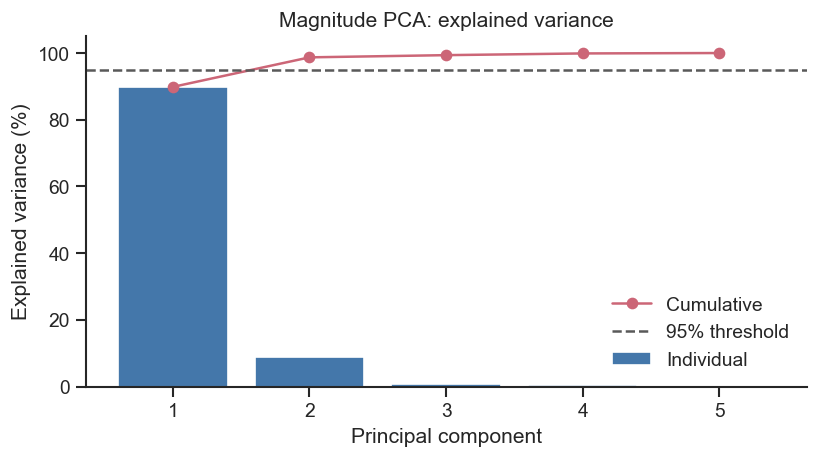

In [7]:
variance_plot(explained, cumulative, "Magnitude PCA: explained variance", "02_magnitude_variance")

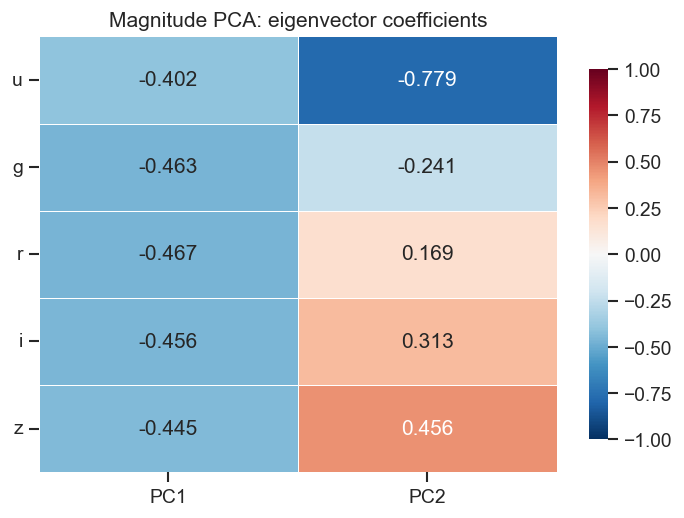

In [8]:
fig, ax = plt.subplots(figsize=(6, 4.5))
heatmap(ax, eigenvectors[:, :k], features, pc_labels(k),
        "Magnitude PCA: eigenvector coefficients", fmt=".3f")
save_figure(fig, "03_magnitude_coefficients")

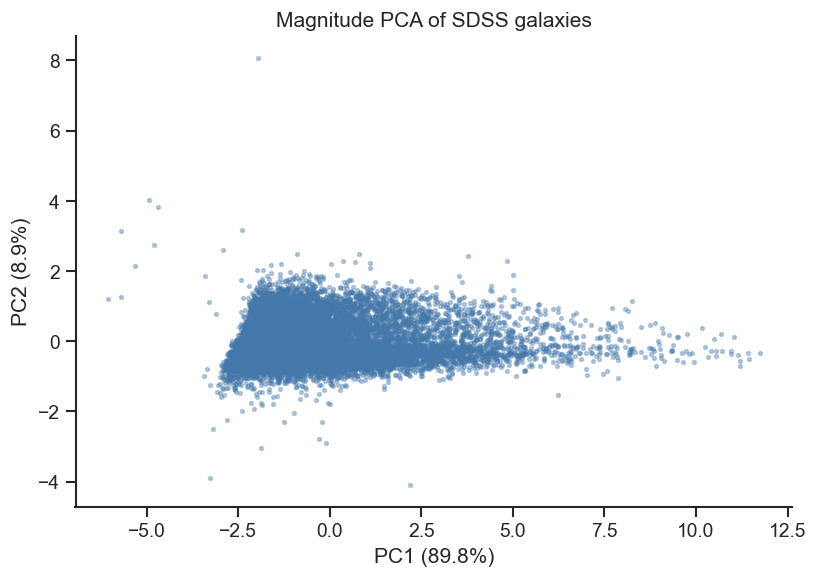

In [9]:
score_plot(scores, explained, "Magnitude PCA of SDSS galaxies", "04_magnitude_scores")

### Physical interpretation

Compare the scores with the mean apparent magnitude, colour indices and redshift. Correlations with colours derived from the input magnitudes help interpret the components but are not independent validation.

In [10]:
# Construct colour indices once for both analyses.
df_col = pd.DataFrame(index=df.index)
df_col["u-g"] = df["u"] - df["g"]
df_col["g-r"] = df["g"] - df["r"]
df_col["r-i"] = df["r"] - df["i"]
df_col["i-z"] = df["i"] - df["z"]
features_col = list(df_col.columns)

physical = df_col.copy()
physical["Mean magnitude"] = df[features].mean(axis=1)
physical["u-z"] = df["u"] - df["z"]
physical["Redshift"] = df["redshift"]
variables = ["Mean magnitude", *features_col, "u-z", "Redshift"]

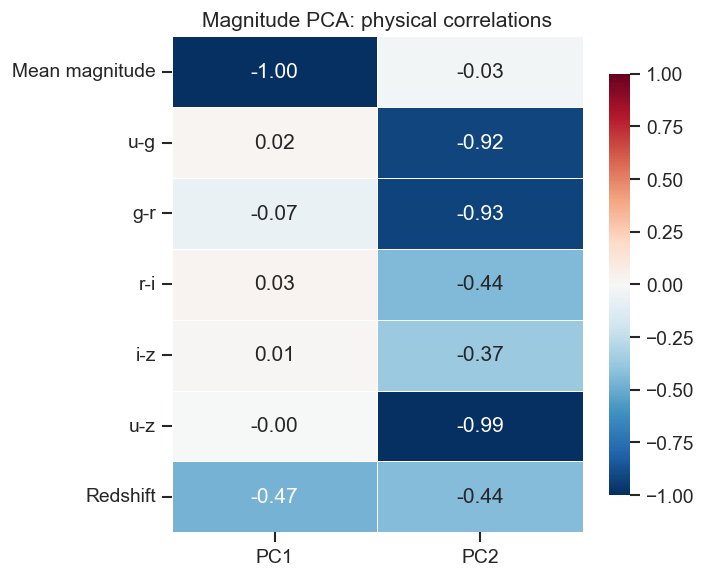

In [11]:
def physical_correlations(physical_data, scores, n):
    names = pc_labels(n)
    result = physical_data.copy()
    result[names] = scores[:, :n]
    return result.corr().loc[variables, names]


corr = physical_correlations(physical, scores, k)
fig, ax = plt.subplots(figsize=(6, 5))
heatmap(ax, corr, variables, pc_labels(k), "Magnitude PCA: physical correlations")
save_figure(fig, "05_magnitude_physical_correlations")

The original run retained two components explaining 98.71% of the standardized magnitude variance. PC1 represents overall apparent brightness and PC2 represents observed colour. Both also correlate moderately with redshift. Neither component directly measures intrinsic luminosity, stellar age or morphology.

## 2. PCA with colour indices

The four adjacent colours remove a common additive shift in magnitudes. They retain spectral-shape information, including possible redshift and measurement effects. We do not include u-z as an additional input because it is the sum of the four colours.

In [12]:
X_col = df_col[features_col].to_numpy()
S_col, eigenvalues_col, eigenvectors_col, explained_col, cumulative_col, k_col, scores_col = correlation_pca(X_col)
PC_col = scores_col[:, :k_col]

print("Eigenvalues:", eigenvalues_col.round(4))
print("Explained variance:", explained_col.round(4))
print("Number of retained PCs:", k_col)
print(f"Total retained variance: {cumulative_col[k_col - 1]:.2%}")

Eigenvalues: [2.0438 1.4193 0.3391 0.1977]
Explained variance: [0.5109 0.3548 0.0848 0.0494]
Number of retained PCs: 3
Total retained variance: 95.06%


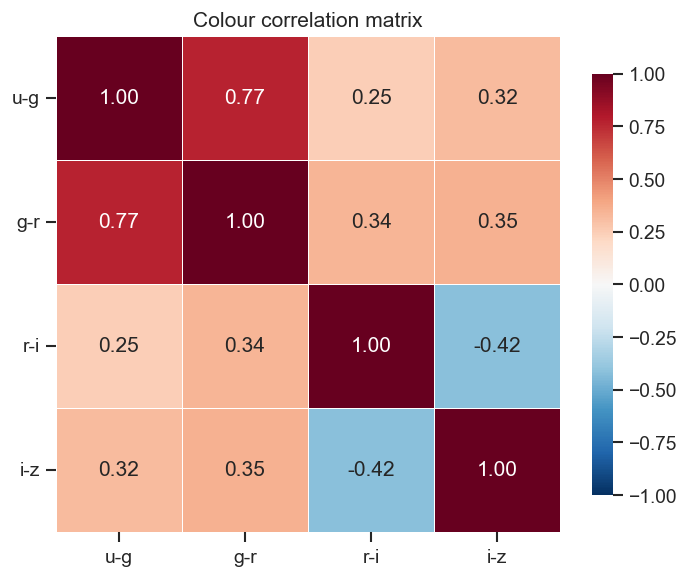

In [13]:
fig, ax = plt.subplots(figsize=(6, 5))
heatmap(ax, S_col, features_col, features_col, "Colour correlation matrix")
save_figure(fig, "06_colour_correlation")

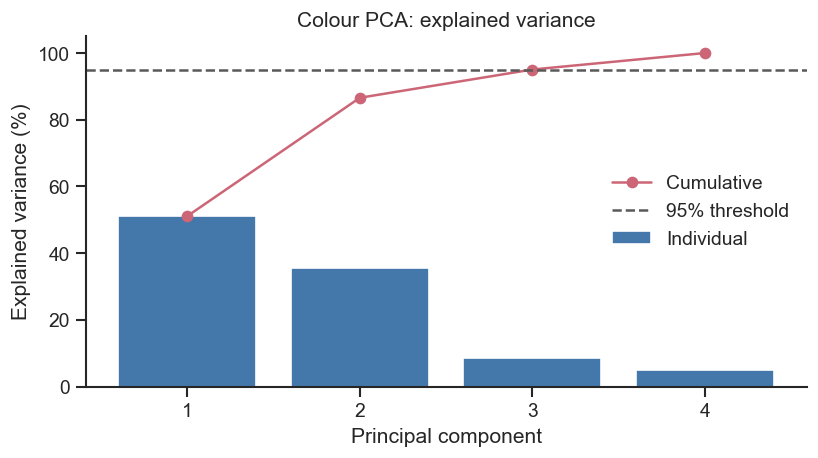

In [14]:
variance_plot(explained_col, cumulative_col, "Colour PCA: explained variance", "07_colour_variance")

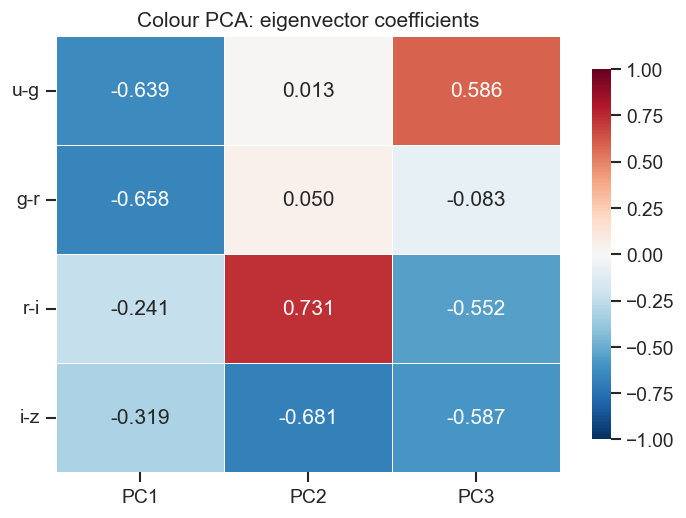

In [15]:
fig, ax = plt.subplots(figsize=(6, 4.5))
heatmap(ax, eigenvectors_col[:, :k_col], features_col, pc_labels(k_col),
        "Colour PCA: eigenvector coefficients", fmt=".3f")
save_figure(fig, "08_colour_coefficients")

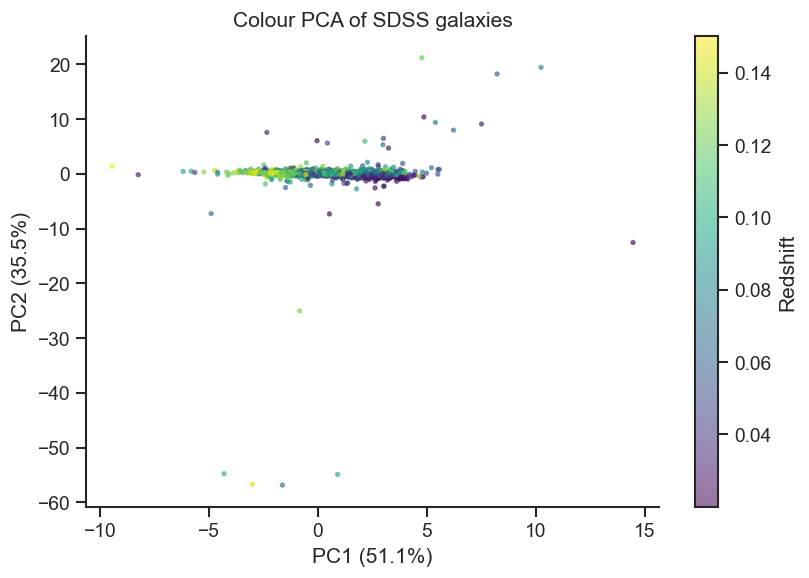

In [16]:
score_plot(scores_col, explained_col, "Colour PCA of SDSS galaxies", "09_colour_scores", df["redshift"])

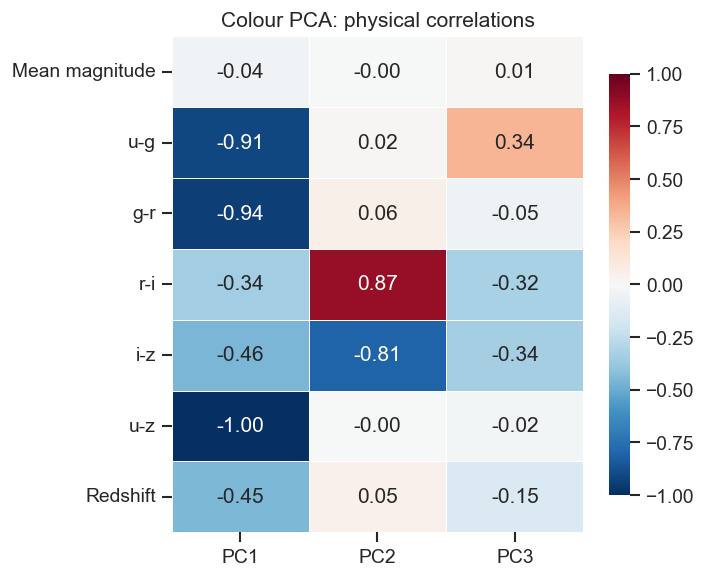

In [17]:
corr_col = physical_correlations(physical, scores_col, k_col)
fig, ax = plt.subplots(figsize=(6, 5))
heatmap(ax, corr_col, variables, pc_labels(k_col), "Colour PCA: physical correlations")
save_figure(fig, "10_colour_physical_correlations")

PC1 tracks overall colour. PC2 contrasts r-i and i-z, which are anticorrelated in the original sample. The score plot suggests that extreme observations may strongly influence this component.

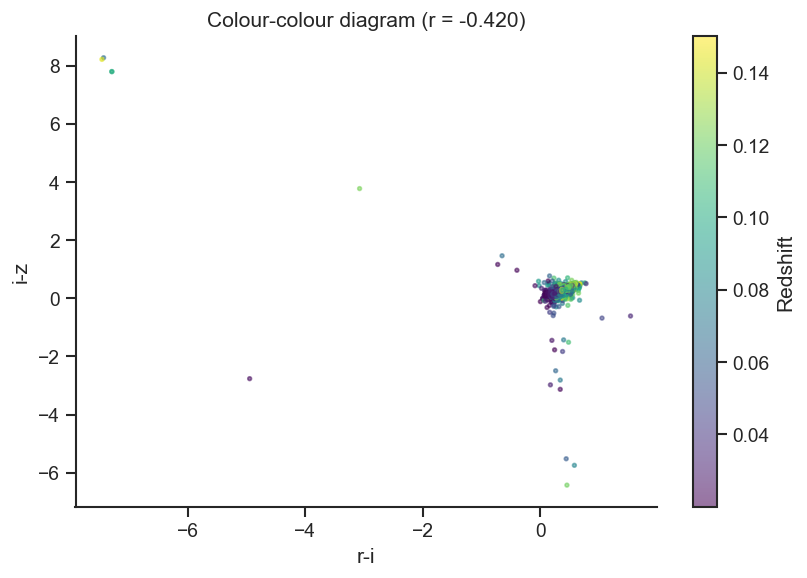

In [18]:
colour_plot(df_col, df["redshift"], "11_colour_colour_full")

## 3. Outlier analysis

First inspect the central population without changing the sample. Then quantify the contribution of extreme PC2 scores and repeat PCA after a quantile cut.

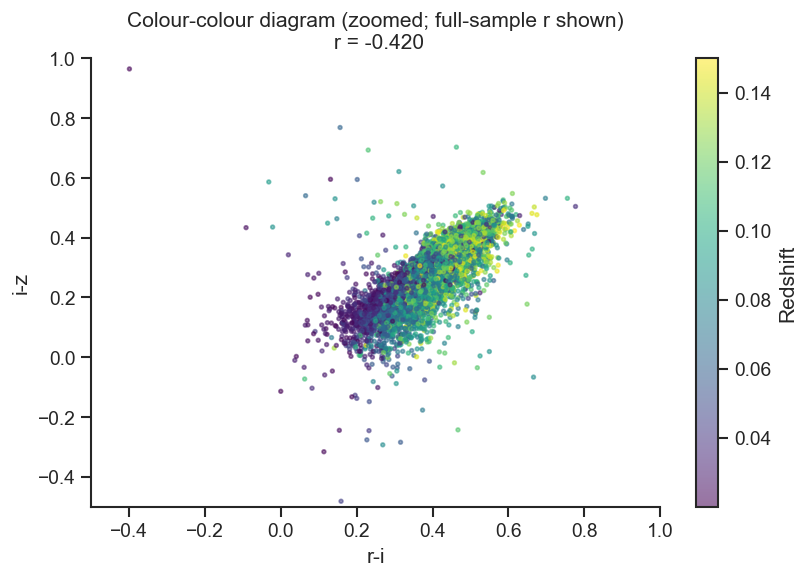

In [19]:
colour_plot(df_col, df["redshift"], "12_colour_colour_zoom", zoom=True)

In [20]:
pc2 = scores_col[:, 1]

# Select the most extreme 1% of PC2 scores
threshold = np.quantile(np.abs(pc2), 0.99)
outliers = np.abs(pc2) >= threshold

# Fraction of PC2 variance contributed by these points
fraction = np.sum(pc2[outliers]**2) / np.sum(pc2**2)

print(f"Number of extreme PC2 scores: {outliers.sum()}")
print(f"Fraction of PC2 variance: {fraction:.2%}")

Number of extreme PC2 scores: 111
Fraction of PC2 variance: 97.58%


The original run found that 111 extreme scores contributed 97.58% of PC2 variance. This is a diagnostic of the original component, not the selection rule used below.

In [21]:
# Exclude observations outside the central 99% of any colour.
lower = df_col.quantile(0.005)
upper = df_col.quantile(0.995)
mask = ((df_col >= lower) & (df_col <= upper)).all(axis=1)
df_col_clean = df_col.loc[mask].copy()

print("Original sample:", len(df_col))
print("Reduced sample:", len(df_col_clean))
print(f"Removed: {(1 - mask.mean()):.2%}")

Original sample: 11030
Reduced sample: 10727
Removed: 2.75%


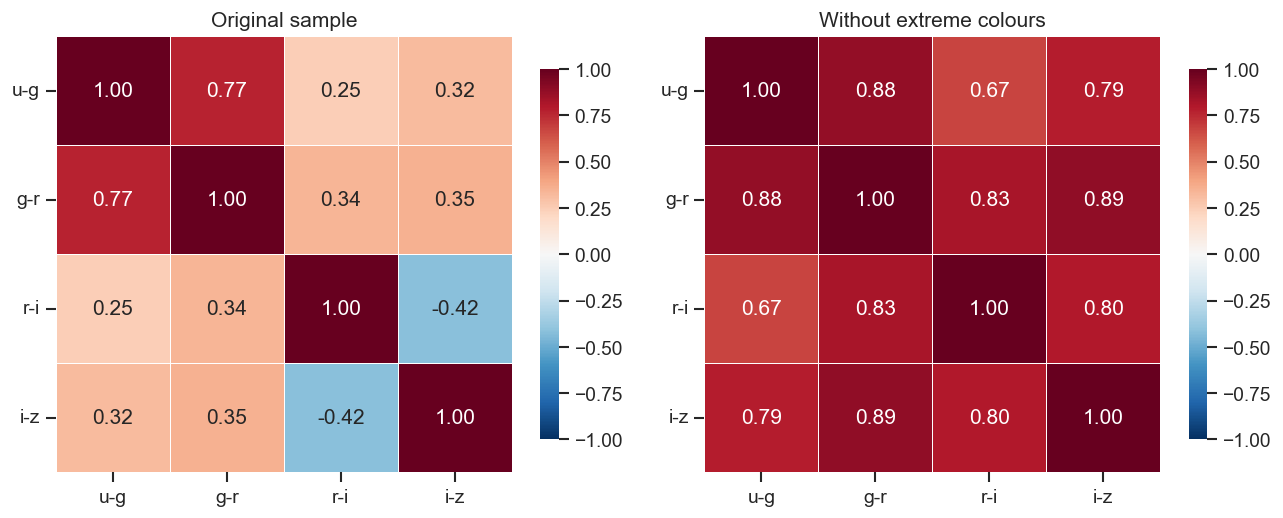

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
heatmap(axes[0], df_col.corr(), features_col, features_col, "Original sample")
heatmap(axes[1], df_col_clean.corr(), features_col, features_col, "Without extreme colours")
save_figure(fig, "13_colour_correlation_comparison")

In [23]:
X_clean = df_col_clean[features_col].to_numpy()
S_clean, eigval_clean, eigvec_clean, explained_clean, cumulative_clean, k_clean, scores_clean = correlation_pca(X_clean)

print("Original PCA:", explained_col.round(4))
print("Reduced sample PCA:", explained_clean.round(4))
print("Number of retained PCs:", k_clean)

Original PCA: [0.5109 0.3548 0.0848 0.0494]
Reduced sample PCA: [0.8577 0.0832 0.0412 0.0179]
Number of retained PCs: 3


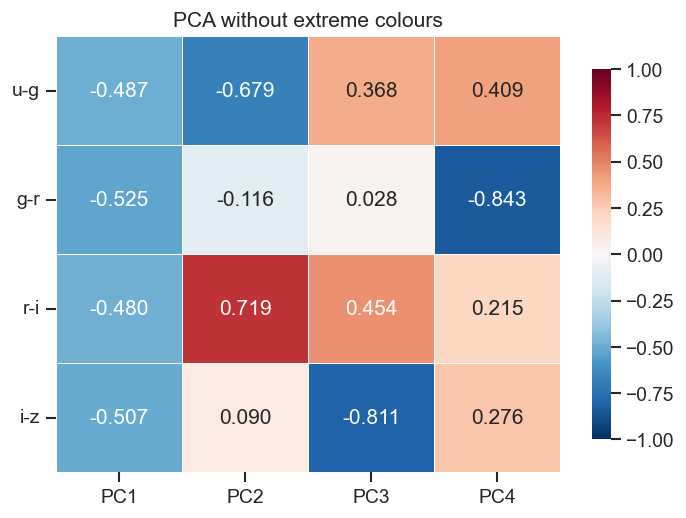

In [24]:
fig, ax = plt.subplots(figsize=(6, 4.5))
heatmap(ax, eigvec_clean, features_col, pc_labels(len(features_col)),
        "PCA without extreme colours", fmt=".3f")
save_figure(fig, "14_clean_colour_coefficients")

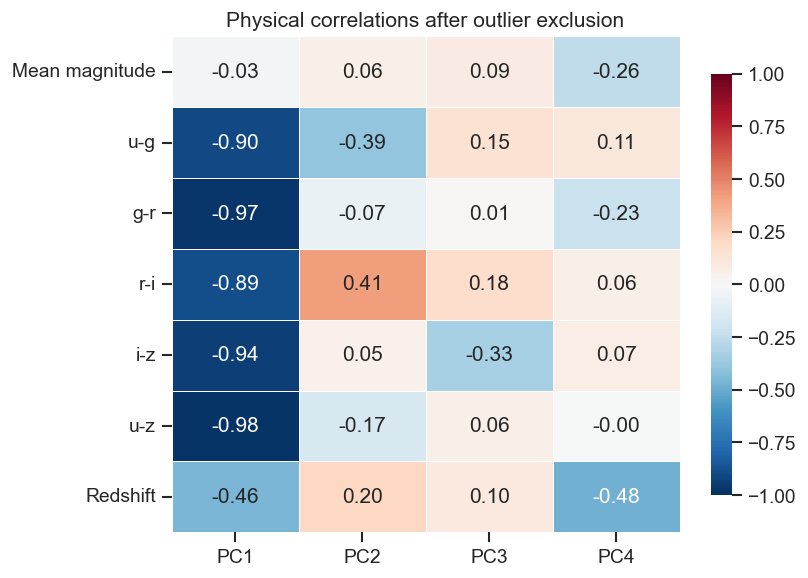

In [25]:
physical_clean = physical.loc[mask].copy()
corr_clean = physical_correlations(physical_clean, scores_clean, len(features_col))
fig, ax = plt.subplots(figsize=(7, 5))
heatmap(ax, corr_clean, variables, pc_labels(len(features_col)),
        "Physical correlations after outlier exclusion")
save_figure(fig, "15_clean_colour_physical_correlations")

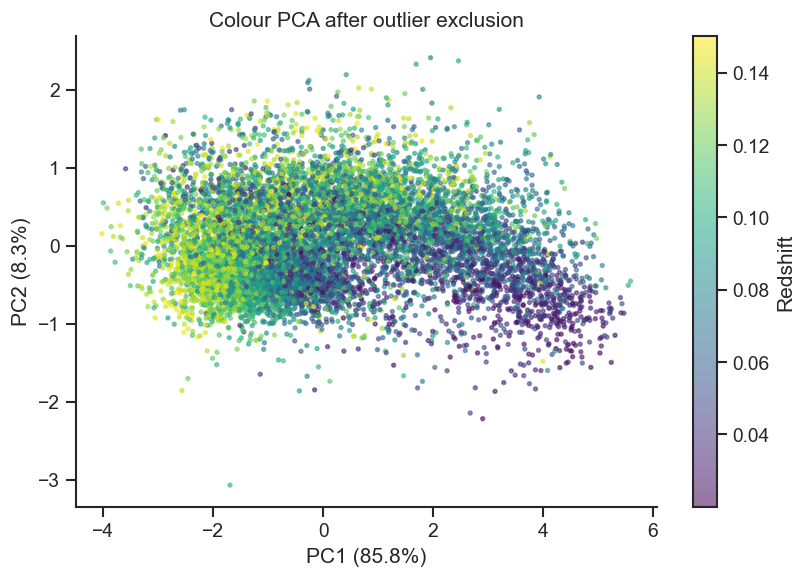

In [26]:
score_plot(scores_clean, explained_clean, "Colour PCA after outlier exclusion",
           "16_clean_colour_scores", physical_clean["Redshift"])

### Main findings

In the original run, excluding 2.75% of the sample removed the r-i / i-z anticorrelation and increased the relative variance explained by PC1 from 51.09% to 85.77%. PC2 decreased from 35.48% to 8.32%. The first component then weighted all four standardized colours almost equally, while the remaining components were harder to associate with specific physical properties.

A shared i-band measurement error can contribute negatively to the covariance of r-i and i-z, but the actual origin of the extreme observations is unknown. The quantile cut is a sensitivity test, not a validated photometric quality cut. The data are standardized again after selection, so the comparison concerns relative explained variance rather than absolute physical variance.